# 高斯函数（Gaussian Function）

> 来源：Weisstein, Eric W. "Gaussian Function." From *MathWorld*—A Wolfram Resource.
> <https://mathworld.wolfram.com/GaussianFunction.html>
>
> 本文是根据该页面整理的笔记（公式与要点）加演示代码，不是原文的转载。原页面以外补充的内容另有标注。

## 定义

归一化（积分为 1）的一维高斯函数，均值为 $\mu$，标准差为 $\sigma$：

$$
f(x)=\frac{1}{\sigma\sqrt{2\pi}}\exp\!\left[-\frac{(x-\mu)^2}{2\sigma^2}\right]
$$

它就是正态分布的概率密度函数，有时也叫"频率曲线"（frequency curve）。最大值在 $x=\mu$ 处。

注意：在超几何函数的语境里，"Gaussian function"有时指的是超几何函数，和这里说的不是一回事。

谱学里常用的是不归一化、带峰高 $A$ 的形式，形状完全相同：

$$
G(x)=A\exp\!\left[-\frac{(x-x_0)^2}{2\sigma^2}\right]
$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.special import erf


def gaussian(x, mu=0.0, sigma=1.0):
    """归一化高斯函数（正态分布概率密度）"""
    return np.exp(-((x - mu) ** 2) / (2 * sigma**2)) / (sigma * np.sqrt(2 * np.pi))

## FWHM 的推导

求半高位置时可以先去掉常数系数，因为它不影响 FWHM。令峰值为 1，设半高点为 $x_0$：

$$
\exp\!\left[-\frac{(x_0-\mu)^2}{2\sigma^2}\right]=\frac12
\;\Longrightarrow\;
(x_0-\mu)^2=2\sigma^2\ln2
\;\Longrightarrow\;
x_0=\mu\pm\sigma\sqrt{2\ln2}
$$

$$
\mathrm{FWHM}=x_+-x_-=2\sqrt{2\ln2}\,\sigma\approx2.3548\,\sigma
$$

## 其他常用性质（原页面未列出，补充）

| 性质 | 结果 |
|---|---|
| 归一化 | $\displaystyle\int_{-\infty}^{\infty}f(x)\,dx=1$ |
| 峰值 | $f(\mu)=\dfrac{1}{\sigma\sqrt{2\pi}}$ |
| 拐点 | $x=\mu\pm\sigma$，函数值为峰值的 $e^{-1/2}\approx0.607$ 倍 |
| 一阶导数 | $f'(x)=-\dfrac{x-\mu}{\sigma^2}f(x)$ |
| 二阶导数 | $f''(x)=\dfrac{(x-\mu)^2-\sigma^2}{\sigma^4}f(x)$ |
| $\mu\pm k\sigma$ 内的面积 | $\operatorname{erf}(k/\sqrt2)$：$k=1,2,3$ 时约为 68.27%、95.45%、99.73% |
| 傅里叶变换（约定 $e^{-2\pi ikx}$） | $\mathcal{F}[f](k)=e^{-2\pi i k\mu}\,e^{-2\pi^2\sigma^2k^2}$，仍是高斯函数 |
| 卷积 | 两个高斯函数卷积仍是高斯函数：$\mu=\mu_1+\mu_2$，$\sigma^2=\sigma_1^2+\sigma_2^2$ |

由卷积性质可以推出，各高斯展宽来源的 FWHM 按平方相加：$\mathrm{FWHM}^2=\mathrm{FWHM}_1^2+\mathrm{FWHM}_2^2$。比如测到的峰宽同时包含仪器分辨率和样品本征的高斯展宽时，可以用这个关系把仪器部分扣掉。

### 数值验证

In [2]:
mu, sigma = 1.0, 0.7

area, _ = quad(gaussian, -np.inf, np.inf, args=(mu, sigma))
half_pt = mu + sigma * np.sqrt(2 * np.log(2))
print(f"面积              = {area:.6f}")
print(f"半高点/峰值        = {gaussian(half_pt, mu, sigma) / gaussian(mu, mu, sigma):.6f}  (理论 0.5)")
print(f"拐点处/峰值        = {gaussian(mu + sigma, mu, sigma) / gaussian(mu, mu, sigma):.6f}  (理论 e^-1/2 = {np.exp(-0.5):.6f})")
for k in (1, 2, 3):
    a, _ = quad(gaussian, mu - k * sigma, mu + k * sigma, args=(mu, sigma))
    print(f"±{k}σ 内的面积      = {a:.4%}  (erf 公式 {erf(k / np.sqrt(2)):.4%})")

面积              = 1.000000
半高点/峰值        = 0.500000  (理论 0.5)
拐点处/峰值        = 0.606531  (理论 e^-1/2 = 0.606531)
±1σ 内的面积      = 68.2689%  (erf 公式 68.2689%)
±2σ 内的面积      = 95.4500%  (erf 公式 95.4500%)
±3σ 内的面积      = 99.7300%  (erf 公式 99.7300%)


### 图示：FWHM、拐点与 ±kσ 区间

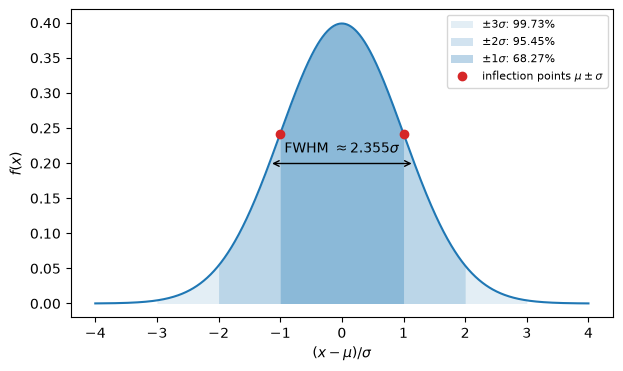

In [3]:
mu, sigma = 0.0, 1.0
x = np.linspace(-4, 4, 1001)
y = gaussian(x, mu, sigma)
peak = gaussian(mu, mu, sigma)
hw = sigma * np.sqrt(2 * np.log(2))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(x, y, color="C0")
for k, alpha in ((3, 0.12), (2, 0.2), (1, 0.3)):
    m = np.abs(x - mu) <= k * sigma
    ax.fill_between(x[m], y[m], color="C0", alpha=alpha, lw=0,
                    label=rf"$\pm{k}\sigma$: {erf(k / np.sqrt(2)):.2%}")
ax.annotate("", xy=(mu + hw, peak / 2), xytext=(mu - hw, peak / 2),
            arrowprops=dict(arrowstyle="<->"))
ax.text(mu, peak / 2 + 0.01, r"FWHM $\approx 2.355\sigma$", ha="center", va="bottom")
ax.plot([mu - sigma, mu + sigma], [gaussian(mu + sigma, mu, sigma)] * 2, "o",
        color="C3", label=r"inflection points $\mu\pm\sigma$")
ax.set_xlabel(r"$(x-\mu)/\sigma$")
ax.set_ylabel("$f(x)$")
ax.legend(fontsize=8)
plt.show()

### 验证卷积性质：宽度按平方相加

In [5]:
dx = 0.001
x = np.arange(-20, 20, dx)
s1, s2 = 0.8, 1.5
conv = np.convolve(gaussian(x, 0, s1), gaussian(x, 0, s2), mode="same") * dx

# 由卷积结果反求 σ（二阶矩）
sigma_num = np.sqrt(np.sum(x**2 * conv) / np.sum(conv))
print(f"卷积后 σ = {sigma_num:.5f}，理论 sqrt(σ1²+σ2²) = {np.hypot(s1, s2):.5f}")
print("与理论高斯的最大偏差:", np.abs(conv - gaussian(x, 0, np.hypot(s1, s2))).max())

卷积后 σ = 1.70000，理论 sqrt(σ1²+σ2²) = 1.70000
与理论高斯的最大偏差: 8.372688276905849e-05


## 二维高斯函数

**圆对称**：$X$、$Y$ 不相关，服从二元正态分布，且标准差相同（$\sigma_x=\sigma_y=\sigma$）：

$$
f(x,y)=\frac{1}{2\pi\sigma^2}\exp\!\left[-\frac{(x-\mu_x)^2+(y-\mu_y)^2}{2\sigma^2}\right]
$$

**椭圆**：标准差不同（$\sigma_x\neq\sigma_y$）：

$$
f(x,y)=\frac{1}{2\pi\sigma_x\sigma_y}\exp\!\left[-\frac{(x-\mu_x)^2}{2\sigma_x^2}-\frac{(y-\mu_y)^2}{2\sigma_y^2}\right]
$$

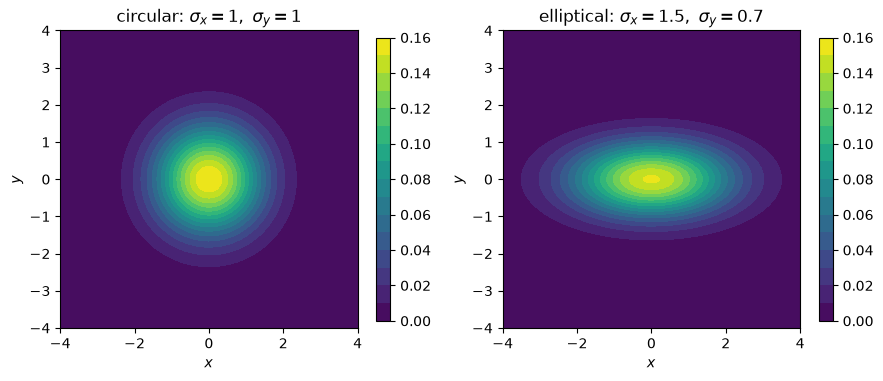

In [6]:
def gaussian_2d(x, y, mux=0.0, muy=0.0, sx=1.0, sy=1.0):
    return np.exp(-((x - mux) ** 2) / (2 * sx**2) - (y - muy) ** 2 / (2 * sy**2)) / (2 * np.pi * sx * sy)


X, Y = np.meshgrid(np.linspace(-4, 4, 301), np.linspace(-4, 4, 301))
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, (sx, sy, title) in zip(axes, [(1, 1, "circular"), (1.5, 0.7, "elliptical")]):
    cs = ax.contourf(X, Y, gaussian_2d(X, Y, sx=sx, sy=sy), levels=15, cmap="viridis")
    ax.set_aspect("equal")
    ax.set_title(rf"{title}: $\sigma_x={sx},\ \sigma_y={sy}$")
    ax.set_xlabel("$x$")
    ax.set_ylabel("$y$")
    fig.colorbar(cs, ax=ax, shrink=0.8)  # 两张图的数值范围不同，各配一个色标
plt.tight_layout()
plt.show()

## 作为切趾函数

高斯函数可以用作切趾函数：

$$
A(x)=\exp\!\left[-\frac{x^2}{2\sigma^2}\right]
$$

把它截断在 $|x|\le a$ 上，做傅里叶变换就得到对应的仪器函数：

$$
I(k)=\int_{-a}^{a}A(x)\,e^{-2\pi ikx}\,dx
=\sigma\sqrt{\frac{\pi}{2}}\,e^{-2\pi^2k^2\sigma^2}
\left[\operatorname{erf}\!\left(\frac{a-2\pi ik\sigma^2}{\sigma\sqrt2}\right)+\operatorname{erf}\!\left(\frac{a+2\pi ik\sigma^2}{\sigma\sqrt2}\right)\right]
$$

它在 $k=0$ 处取最大值：

$$
I_{\max}=I(0)=\sigma\sqrt{2\pi}\,\operatorname{erf}\!\left(\frac{a}{\sigma\sqrt2}\right)
$$

当 $a\to\infty$（不截断）时：

$$
\lim_{a\to\infty}I(k)=\sigma\sqrt{2\pi}\,e^{-2\pi^2k^2\sigma^2}
$$

这就是高斯函数的傅里叶变换仍是高斯函数。截断越少（$a/\sigma$ 越大），仪器函数的旁瓣越小。

a=0.5: 闭式与数值积分最大偏差 = 4.05e-15
a=1.0: 闭式与数值积分最大偏差 = 2.29e-15
a=2.0: 闭式与数值积分最大偏差 = 8.88e-16


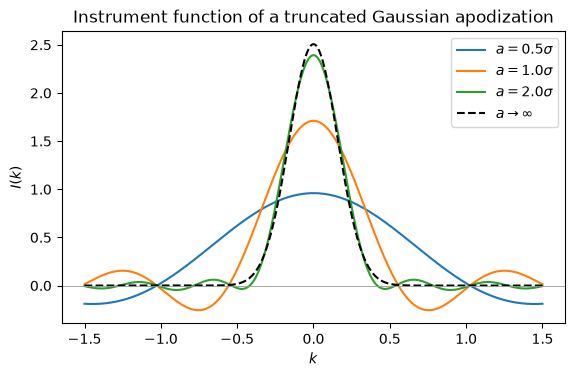

In [7]:
sigma = 1.0
k = np.linspace(-1.5, 1.5, 601)


def instrument(k, a, sigma):
    """原页面给出的闭式（复数 erf 用 scipy.special.erf，支持复数输入）"""
    z1 = (a - 2j * np.pi * k * sigma**2) / (sigma * np.sqrt(2))
    z2 = (a + 2j * np.pi * k * sigma**2) / (sigma * np.sqrt(2))
    return (sigma * np.sqrt(np.pi / 2) * np.exp(-2 * np.pi**2 * k**2 * sigma**2) * (erf(z1) + erf(z2))).real


def instrument_numeric(k, a, sigma):
    """直接对截断的高斯做数值傅里叶积分（被积函数为偶函数，只剩余弦项）"""
    return np.array([quad(lambda x: np.exp(-x**2 / (2 * sigma**2)) * np.cos(2 * np.pi * kk * x), -a, a)[0]
                     for kk in k])


fig, ax = plt.subplots(figsize=(6.5, 3.8))
for a in (0.5, 1.0, 2.0):
    ax.plot(k, instrument(k, a, sigma), label=rf"$a={a}\sigma$")
    print(f"a={a}: 闭式与数值积分最大偏差 = {np.abs(instrument(k, a, sigma) - instrument_numeric(k, a, sigma)).max():.2e}")
ax.plot(k, sigma * np.sqrt(2 * np.pi) * np.exp(-2 * np.pi**2 * k**2 * sigma**2), "k--",
        label=r"$a\to\infty$")
ax.axhline(0, color="0.6", lw=0.6)
ax.set_xlabel("$k$")
ax.set_ylabel("$I(k)$")
ax.set_title("Instrument function of a truncated Gaussian apodization")
ax.legend()
plt.show()

## 补充：谱峰拟合里的高斯、洛伦兹与 GL 混合线形

在 FWHM 相同的条件下，高斯峰在峰位附近更"胖"，尾部却衰减得快得多。XPS 拟合里常用伪 Voigt / GL 混合线形，把两者按比例 $\eta$ 线性组合：

$$
\mathrm{pV}(x)=\eta\,L(x)+(1-\eta)\,G(x),\qquad 0\le\eta\le1
$$

这里 $L$ 和 $G$ 取相同的 FWHM（这里都化成峰高为 1 的形式）。不同软件对 GL 比例的定义（是加和还是乘积、百分比指的是哪一项）不完全相同，使用时要看清楚。

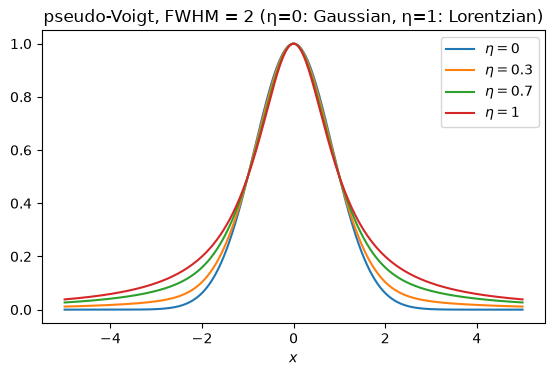

In [8]:
def gauss_peak(x, x0, fwhm):
    return np.exp(-4 * np.log(2) * (x - x0) ** 2 / fwhm**2)  # 峰高为 1


def lorentz_peak(x, x0, fwhm):
    return 1 / (1 + 4 * (x - x0) ** 2 / fwhm**2)  # 峰高为 1


def pseudo_voigt(x, x0, fwhm, eta):
    return eta * lorentz_peak(x, x0, fwhm) + (1 - eta) * gauss_peak(x, x0, fwhm)


x = np.linspace(-5, 5, 1001)
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for eta in (0, 0.3, 0.7, 1):
    ax.plot(x, pseudo_voigt(x, 0, 2, eta), label=rf"$\eta={eta}$")
ax.set_xlabel("$x$")
ax.set_title("pseudo-Voigt, FWHM = 2 (η=0: Gaussian, η=1: Lorentzian)")
ax.legend()
plt.show()

## 相关条目（MathWorld）

- [Normal Distribution](https://mathworld.wolfram.com/NormalDistribution.html)
- [Bivariate Normal Distribution](https://mathworld.wolfram.com/BivariateNormalDistribution.html)
- [Fourier Transform—Gaussian](https://mathworld.wolfram.com/FourierTransformGaussian.html)
- [Erf](https://mathworld.wolfram.com/Erf.html)、[Erfc](https://mathworld.wolfram.com/Erfc.html)
- [Lorentzian Function](https://mathworld.wolfram.com/LorentzianFunction.html)
- [Full Width at Half Maximum](https://mathworld.wolfram.com/FullWidthatHalfMaximum.html)
- [Hyperbolic Secant](https://mathworld.wolfram.com/HyperbolicSecant.html)
- [Owen T-Function](https://mathworld.wolfram.com/OwenT-Function.html)
- [Witch of Agnesi](https://mathworld.wolfram.com/WitchofAgnesi.html)
原页面的参考文献：MacTutor History of Mathematics Archive, "Frequency Curve."

In [1]:
print("hello world")

hello world
